# PAF Project Group 6 — Task 3: Predictive Modelling
## Golden Hour Fatality Triage

**Contributors:** Joao (Person 1): problem framing, metrics & baseline · Pedro (Person 4): tree-based ensembles · Nuno (Person 5): non-tree models

**Business question.** When an emergency call arrives (t=0), should the dispatcher send a standard patrol / basic ambulance, or an immediate Advanced Life Support (ALS) unit or helicopter?

**Prediction.** Probability that the crash is fatal (`is_fatal = 1` when `accident_classification == 2`), using only information known at call intake.

This notebook reproduces the problem framing, metrics and baseline benchmark defined by Joao (see `contributions/person1_joao_problem_framing/`). Pedro and Nuno add their models in Section 7 and are evaluated with the same functions.

**Run `Task2_Data_Understanding_Preparation.ipynb` first:** it cleans the data, engineers the features, makes the split and saves them to `data/processed/`.

| Section | Content |
|---|---|
| 1 | Setup & loading the prepared data (from Task 2) |
| 2 | Data preparation recap |
| 3 | Target & base rates |
| 4 | Out-of-time split & feature sets |
| 5 | Metrics: why not accuracy, Top-15% rule, economic threshold p* |
| 6 | Baseline benchmark: Dummy vs. Balanced Logistic Regression |
| 7 | Advanced models: tree ensembles (Pedro), non-tree models & final comparison (Nuno) |
| 8 | Originality: cost-benefit of ALS capacity, GPS hotspots & interactive map (Nuno) |

## 1. Setup & data loading

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib
import json

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [2]:
# Prepared by Task2_Data_Understanding_Preparation.ipynb (Section 9).
# Works locally (repo layout) and in Colab (upload the files from data/processed/).
PROCESSED = Path("../data/processed")
if not (PROCESSED / "train.csv").exists():
    from google.colab import files
    files.upload()  # train.csv, val.csv, test.csv, features.json, preprocessor.joblib
    PROCESSED = Path(".")

train = pd.read_csv(PROCESSED / "train.csv")
val = pd.read_csv(PROCESSED / "val.csv")
test = pd.read_csv(PROCESSED / "test.csv")
feature_lists = json.loads((PROCESSED / "features.json").read_text())
preprocessor = joblib.load(PROCESSED / "preprocessor.joblib")

df = pd.concat([train, val, test])
print(f"Prepared data: {len(df):,} rows (train {len(train):,} · val {len(val):,} · test {len(test):,})")

Prepared data: 149,999 rows (train 130,870 · val 9,073 · test 10,056)


## 2. Data preparation recap

Done in the Task 2 notebook (Section 9), based on the data-quality audit:
- **Dropped corrupted row 57163** (more than 10 missing features).
- **Imputed the 90 missing `road_direction` values** with the Train mode.
- **Excluded `latitude` / `longitude`**: 100% missing 2007–2016 (2017 GPS cliff).
- **Excluded `date` / `year`** as predictors: after the 2015 e-DAT reporting change, year captures *how crashes were logged*, not road risk.
- **Engineered features:** day of week, weekend flag, cyclical month, capped km, historical segment risk (fitted on Train only).

## 3. Target & base rates

Fatal crashes overall (2007-2025): 7,222 (4.81%)
Non-fatal overall:                 95.19%


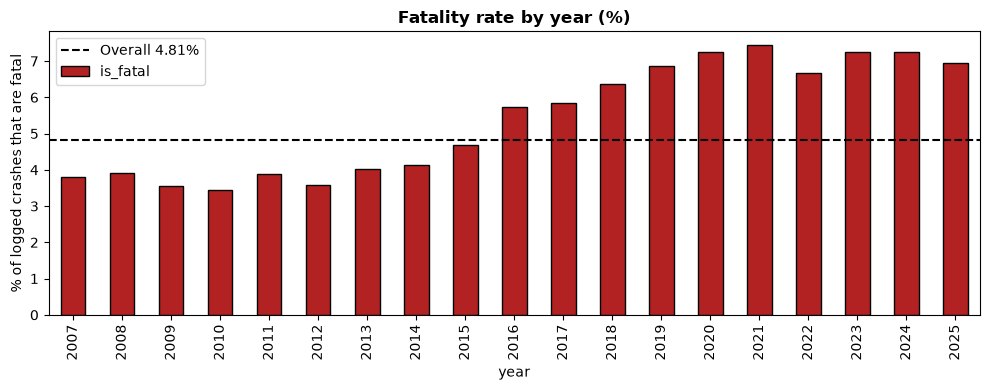

In [3]:
overall_rate = df["is_fatal"].mean()
print(f"Fatal crashes overall (2007-2025): {df['is_fatal'].sum():,} ({overall_rate:.2%})")
print(f"Non-fatal overall:                 {1 - overall_rate:.2%}")

rate_by_year = df.groupby("year")["is_fatal"].mean() * 100
ax = rate_by_year.plot(kind="bar", color="firebrick", edgecolor="black", figsize=(10, 4))
ax.axhline(overall_rate * 100, ls="--", color="black", label=f"Overall {overall_rate:.2%}")
ax.set_title("Fatality rate by year (%)", fontweight="bold")
ax.set_ylabel("% of logged crashes that are fatal")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Out-of-time split

No random shuffling: the model is trained on the past and evaluated on the most recent years, as it would be used in production. The split was made in the Task 2 notebook.

| Set | Years |
|---|---|
| Train | 2007–2021 |
| Validation | 2022–2023 |
| Test | 2024–2025 |

In [4]:
split_summary = pd.DataFrame({
    "Rows": [len(train), len(val), len(test)],
    "Fatal rate (%)": [s["is_fatal"].mean() * 100 for s in (train, val, test)],
}, index=["Train 2007-2021", "Validation 2022-2023", "Test 2024-2025"]).round(2)
split_summary

,Rows,Fatal rate (%)
Train 2007-2021,130870,4.49
Validation 2022-2023,9073,6.97
Test 2024-2025,10056,7.11


Two feature sets:
- **Baseline features** (19): the original road, location and time-of-day columns, as defined by Joao. Used for the baseline in Section 6.
- **Full features** (24): baseline plus the engineered features from Task 2. Used for the advanced models in Section 7, with the encoder and scaler fitted on Train (`preprocessor`).

In [5]:
BASE_CATEGORICAL = feature_lists["base_categorical"]
BASE_NUMERIC = feature_lists["base_numeric"]
BASE_FEATURES = BASE_CATEGORICAL + BASE_NUMERIC
FEATURES = feature_lists["categorical"] + feature_lists["numeric"]

y_train, y_val, y_test = train["is_fatal"], val["is_fatal"], test["is_fatal"]
X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]

print(f"Baseline features ({len(BASE_FEATURES)}): {BASE_FEATURES}")
print(f"Full features ({len(FEATURES)}): {FEATURES}")
print("All known at t=0 (road geometry, location marker, calendar, time of day)")

Baseline features (19): ['roadway_type', 'area_type', 'time_of_day', 'highway_type', 'road_direction', 'km', 'Straight', 'Curve', 'Crossing', 'Downhill', 'Uphill', 'Road_Intersection', 'Roundabout', 'Regulated_Uturn', 'Roadworks', 'Overpass', 'Bridge', 'Temporary_Detour', 'Tunnel']
Full features (24): ['roadway_type', 'area_type', 'time_of_day', 'highway_type', 'road_direction', 'day_of_week', 'km_capped', 'Straight', 'Curve', 'Crossing', 'Downhill', 'Uphill', 'Road_Intersection', 'Roundabout', 'Regulated_Uturn', 'Roadworks', 'Overpass', 'Bridge', 'Temporary_Detour', 'Tunnel', 'is_weekend', 'month_sin', 'month_cos', 'segment_risk']
All known at t=0 (road geometry, location marker, calendar, time of day)


## 5. Metrics

### Why not accuracy
A model that always predicts "no fatality" looks excellent on accuracy but catches no deaths.

In [6]:
accuracy_always_no = 1 - y_test.mean()
print(f"'No fatality, ever' on the 2024-2025 test set: accuracy {accuracy_always_no:.2%}, recall 0.00%")

'No fatality, ever' on the 2024-2025 test set: accuracy 92.89%, recall 0.00%


### Metrics used
- **PR-AUC**: ranking quality on a rare event (a random model scores the base rate).
- **Recall / Precision / Lift @ Top 15%**: ALS capacity covers 15% of calls. Of all fatal crashes, how many fall in the 15% highest-risk calls, and how much better than random?
- **Brier score**: are the predicted probabilities trustworthy (calibration)? Lower is better.
- ROC-AUC reported for reference.

In [7]:
CAPACITY = 0.15  # share of calls that ALS can serve


def top_k_metrics(y_true, y_prob, k=CAPACITY):
    """Recall, precision and lift when dispatching ALS to the top-k share of highest-risk calls."""
    y_true = np.asarray(y_true)
    if np.ptp(y_prob) == 0:  # constant scores cannot rank: top-k is a random pick
        return k, y_true.mean(), 1.0
    n_top = int(np.ceil(len(y_true) * k))
    top_idx = np.argsort(-y_prob, kind="stable")[:n_top]
    recall = y_true[top_idx].sum() / y_true.sum()
    precision = y_true[top_idx].mean()
    return recall, precision, recall / k


def evaluate(name, y_true, y_prob):
    recall, precision, lift = top_k_metrics(y_true, y_prob)
    return pd.Series({
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Recall@15%": recall,
        "Precision@15%": precision,
        "Lift@15%": lift,
        "Brier": brier_score_loss(y_true, y_prob),
    }, name=name)

### Economic threshold p*
Dispatching ALS costs about €2,500; a prevented death is valued at about €50,000. Dispatch is worth it when expected benefit exceeds cost:

$$p \cdot B > C \;\Rightarrow\; p^* = \frac{C}{B}$$

In [8]:
COST_ALS = 2_500
BENEFIT_PREVENTED_DEATH = 50_000
p_star = COST_ALS / BENEFIT_PREVENTED_DEATH
print(f"p* = {COST_ALS:,} / {BENEFIT_PREVENTED_DEATH:,} = {p_star:.1%}")
print(f"Test-set base rate = {y_test.mean():.2%} > p*, so capacity (Top 15%) is the binding constraint.")

p* = 2,500 / 50,000 = 5.0%
Test-set base rate = 7.11% > p*, so capacity (Top 15%) is the binding constraint.


## 6. Baseline benchmark

1. **Dummy classifier**: always predicts the majority class ("no fatality"), so every crash gets probability 0.
2. **Balanced Logistic Regression**: one-hot encoded categoricals + scaled numeric features, `class_weight="balanced"` to counter the 5% fatal rate. Preprocessing is fitted on Train only.

In [9]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(train[BASE_FEATURES], y_train)
p_dummy = dummy.predict_proba(test[BASE_FEATURES])[:, 1]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), BASE_CATEGORICAL),
    ("num", StandardScaler(), BASE_NUMERIC),
])
logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
])
logreg.fit(train[BASE_FEATURES], y_train)
p_logreg = logreg.predict_proba(test[BASE_FEATURES])[:, 1]

results = pd.DataFrame([
    evaluate("Dummy (Baseline)", y_test, p_dummy),
    evaluate("Balanced Logistic Regression", y_test, p_logreg),
])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552


### Comparison with Joao's reported numbers

The Dummy row reproduces exactly. The logistic regression lands slightly above Joao's figures: their exact feature set and preprocessing were not shared, so small differences are expected. **The numbers in this notebook are the reproducible ones to use on the slides.**

In [10]:
joao = pd.DataFrame({
    "ROC-AUC": [0.5000, 0.6643], "PR-AUC": [0.0711, 0.1158],
    "Recall@15%": [0.1500, 0.2895], "Precision@15%": [0.0711, 0.1372],
    "Lift@15%": [1.00, 1.93], "Brier": [0.0711, 0.2499],
}, index=results.index)

comparison = pd.concat({"Joao (reported)": joao, "This notebook": results}, axis=1)
comparison.T.round(4)

Dummy (Baseline)  Balanced Logistic Regression
Joao (reported) ROC-AUC                  0.5000                        0.6643
                PR-AUC                   0.0711                        0.1158
                Recall@15%               0.1500                        0.2895
                Precision@15%            0.0711                        0.1372
                Lift@15%                 1.0000                        1.9300
                Brier                    0.0711                        0.2499
This notebook   ROC-AUC                  0.5000                        0.6659
                PR-AUC                   0.0711                        0.1221
                Recall@15%               0.1500                        0.3119
                Precision@15%            0.0711                        0.1478
                Lift@15%                 1.0000                        2.0793
                Brier                    0.0711                        0.2552

### Calibration (open flag from Joao)

Class balancing inflates probabilities: the Brier score is much worse than the dummy's. Before applying p* = 5%, the probabilities are re-calibrated on the **validation** set (isotonic regression, model frozen). Ranking metrics barely change; Brier should drop sharply.

In [11]:
logreg_cal = CalibratedClassifierCV(FrozenEstimator(logreg), method="isotonic")
logreg_cal.fit(val[BASE_FEATURES], y_val)
p_logreg_cal = logreg_cal.predict_proba(test[BASE_FEATURES])[:, 1]

results = pd.concat([results, evaluate("Balanced LR + isotonic calibration", y_test, p_logreg_cal).to_frame().T])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552
Balanced LR + isotonic calibration,0.6679,0.1180,0.3105,0.1471,2.0699,0.0645


In [12]:
dispatched = p_logreg_cal >= p_star
print(f"Calls above p* = {p_star:.0%}: {dispatched.mean():.1%} of test calls "
      f"(capacity is {CAPACITY:.0%})")
print(f"Fatal crashes among them: {y_test[dispatched].sum()} of {y_test.sum()} "
      f"({y_test[dispatched].sum() / y_test.sum():.1%})")

Calls above p* = 5%: 62.9% of test calls (capacity is 15%)
Fatal crashes among them: 592 of 715 (82.8%)


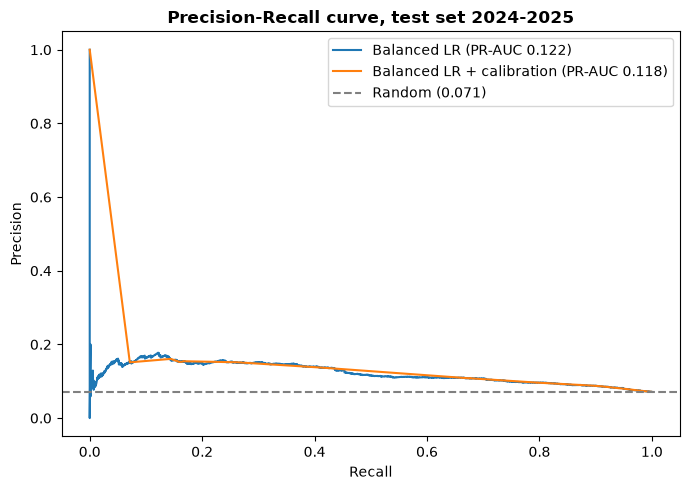

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in [("Balanced LR", p_logreg), ("Balanced LR + calibration", p_logreg_cal)]:
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Random ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curve, test set 2024-2025", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Advanced models (Pedro & Nuno)

Use the full feature set `X_train / X_val / X_test`, tune on **validation only**, and touch the test set once at the end.

- Linear models / neural nets: put the fitted `preprocessor` in front, e.g. `Pipeline([("prep", preprocessor), ("model", ...)])`. It is already fitted on Train, so wrap it with `FrozenEstimator(preprocessor)` to avoid refitting.
- Tree-based models (Random Forest, Gradient Boosting): the prepared columns can be used directly.
- Re-calibrate probabilities on validation before using p* (see Section 6).
- Worth testing (Task 2 finding): training on 2015–2021 only (`train[train["year"] >= 2015]`), after the e-DAT reporting change.

Add each model to the results table with:

```python
results = pd.concat([results, evaluate("My model", y_test, p_my_model).to_frame().T])
```

### 7.1 Model 1: Tree-based ensembles (Pedro)

**Why trees.** Fatality risk comes from combinations of conditions (e.g. rural *and* night *and* downhill), which a linear model can only capture if we hand-craft the interactions. Tree ensembles learn these interactions directly, need no scaling and handle the categorical codes natively.

Two ensemble strategies are compared:
- **Random Forest** (bagging): many deep, decorrelated trees averaged together. Robust, few hyperparameters.
- **Histogram Gradient Boosting** (boosting, scikit-learn's LightGBM-style implementation): shallow trees fitted one after another on the errors of the previous ones. Usually the strongest model on tabular data.

Both use class weights (`balanced`) to counter the 5% fatal rate, the same choice as the baseline. Hyperparameters are chosen on **Validation 2022–2023** by PR-AUC; the test set is used once, at the end.

In [14]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance

CATEGORICAL = feature_lists["categorical"]


def make_rf(**params):
    return RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=RANDOM_STATE, **params)


def make_hgb(**params):
    return HistGradientBoostingClassifier(class_weight="balanced", categorical_features=CATEGORICAL,
                                          min_samples_leaf=50, l2_regularization=1.0,
                                          early_stopping=False, random_state=RANDOM_STATE, **params)


def validation_score(model, X_fit=X_train, y_fit=y_train):
    # Fit on Train and score ranking quality on Validation (the test set is not touched)
    model.fit(X_fit, y_fit)
    p = model.predict_proba(X_val)[:, 1]
    _, _, lift = top_k_metrics(y_val, p)
    return {"PR-AUC (val)": average_precision_score(y_val, p), "Lift@15% (val)": lift}

#### Tuning on validation

A small grid per model. For Random Forest the key lever is how deep the trees grow (`max_depth`, `min_samples_leaf`); for Gradient Boosting it is the learning rate, tree size and number of trees.

In [15]:
rf_grid = [{"max_depth": d, "min_samples_leaf": leaf} for d in (8, 12, None) for leaf in (20, 50)]
hgb_grid = [{"learning_rate": lr, "max_leaf_nodes": leaves, "max_iter": n}
            for lr, leaves, n in [(0.1, 15, 300), (0.1, 31, 300), (0.03, 31, 300),
                                  (0.03, 15, 300), (0.03, 15, 150), (0.03, 7, 300), (0.01, 15, 600)]]

tuning = []
for params in rf_grid:
    tuning.append({"Model": "Random Forest", "Params": params, **validation_score(make_rf(**params))})
for params in hgb_grid:
    tuning.append({"Model": "Gradient Boosting", "Params": params, **validation_score(make_hgb(**params))})

tuning = pd.DataFrame(tuning).sort_values("PR-AUC (val)", ascending=False)
tuning.round(4)

,Model,Params,PR-AUC (val),Lift@15% (val)
10,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",0.1347,2.2152
12,Gradient Boosting,"{'learning_rate': 0.01, 'max_leaf_nodes': 15, ...",0.1328,2.2257
11,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 7, '...",0.1323,2.2574
9,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, ...",0.1300,2.2574
8,Gradient Boosting,"{'learning_rate': 0.03, 'max_leaf_nodes': 31, ...",0.1288,2.1624
1,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 50}",0.1273,2.0042
3,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 50}",0.1269,2.0148
0,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 20}",0.1262,1.9937
2,Random Forest,"{'max_depth': 12, 'min_samples_leaf': 20}",0.1259,2.0464
5,Random Forest,"{'max_depth': None, 'min_samples_leaf': 50}",0.1259,2.0675


In [16]:
best_rf_params = tuning.loc[tuning["Model"] == "Random Forest", "Params"].iloc[0]
best_hgb_params = tuning.loc[tuning["Model"] == "Gradient Boosting", "Params"].iloc[0]
print(f"Best Random Forest:     {best_rf_params}")
print(f"Best Gradient Boosting: {best_hgb_params}")

Best Random Forest:     {'max_depth': 8, 'min_samples_leaf': 50}
Best Gradient Boosting: {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'max_iter': 150}


Smaller, more regularised models win on validation: deeper forests and more boosting rounds start fitting noise in the training years, which does not carry over to 2022–2023.

#### Training window: 2007–2021 vs. 2015–2021

The 2015 e-DAT reporting change (Task 2, Section 4) means older years were logged differently. We check whether training only on the post-change years helps.

In [17]:
recent = train["year"] >= 2015
window = pd.DataFrame({
    "2007-2021 (all Train)": validation_score(make_hgb(**best_hgb_params)),
    "2015-2021 (post e-DAT)": validation_score(make_hgb(**best_hgb_params), X_train[recent], y_train[recent]),
}).T
print(f"Rows: all Train {len(X_train):,} · post e-DAT {recent.sum():,}")
window.round(4)

Rows: all Train 130,870 · post e-DAT 39,540


,PR-AUC (val),Lift@15% (val)
2007-2021 (all Train),0.1347,2.2152
2015-2021 (post e-DAT),0.1366,2.2152


Both windows score about the same on validation. We keep **all Train years (2007–2021)**: more than twice the data for no loss in ranking, and the reporting drift is handled by re-calibrating the probabilities on validation.

#### Final fit, calibration and test-set scoring

The two tuned models are refitted on Train, re-calibrated on Validation (model frozen, as for the baseline in Section 6), and scored **once** on Test 2024–2025.

We use **sigmoid (Platt) calibration** rather than isotonic: isotonic regression maps scores to a step function, so many calls end up with the same probability and the Top-15% ranking gets blurred by ties. The sigmoid is strictly increasing, so it fixes the probabilities (Brier) while keeping the ranking of the model exactly as it is.

In [18]:
rf = make_rf(**best_rf_params).fit(X_train, y_train)
hgb = make_hgb(**best_hgb_params).fit(X_train, y_train)

rf_cal = CalibratedClassifierCV(FrozenEstimator(rf), method="sigmoid").fit(X_val, y_val)
hgb_cal = CalibratedClassifierCV(FrozenEstimator(hgb), method="sigmoid").fit(X_val, y_val)

p_rf, p_rf_cal = rf.predict_proba(X_test)[:, 1], rf_cal.predict_proba(X_test)[:, 1]
p_hgb, p_hgb_cal = hgb.predict_proba(X_test)[:, 1], hgb_cal.predict_proba(X_test)[:, 1]

results = pd.concat([results, pd.DataFrame([
    evaluate("Random Forest", y_test, p_rf),
    evaluate("Random Forest + sigmoid calibration", y_test, p_rf_cal),
    evaluate("Gradient Boosting", y_test, p_hgb),
    evaluate("Gradient Boosting + sigmoid calibration", y_test, p_hgb_cal),
])])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552
Balanced LR + isotonic calibration,0.6679,0.1180,0.3105,0.1471,2.0699,0.0645
Random Forest,0.6640,0.1245,0.3119,0.1478,2.0793,0.2331
Random Forest + sigmoid calibration,0.6640,0.1245,0.3119,0.1478,2.0793,0.0645
Gradient Boosting,0.6731,0.1264,0.3147,0.1491,2.0979,0.2417
Gradient Boosting + sigmoid calibration,0.6731,0.1264,0.3147,0.1491,2.0979,0.0644


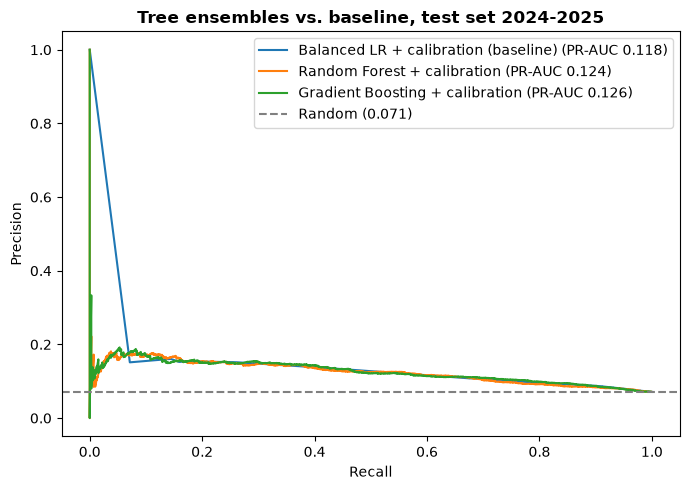

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in [("Balanced LR + calibration (baseline)", p_logreg_cal),
                ("Random Forest + calibration", p_rf_cal),
                ("Gradient Boosting + calibration", p_hgb_cal)]:
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Random ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Tree ensembles vs. baseline, test set 2024-2025", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

#### What the model learned

Permutation importance on **Validation**: how much PR-AUC drops when one feature is randomly shuffled. Unlike the built-in tree importances, it is measured on unseen data and is not biased towards continuous features such as `km_capped`.

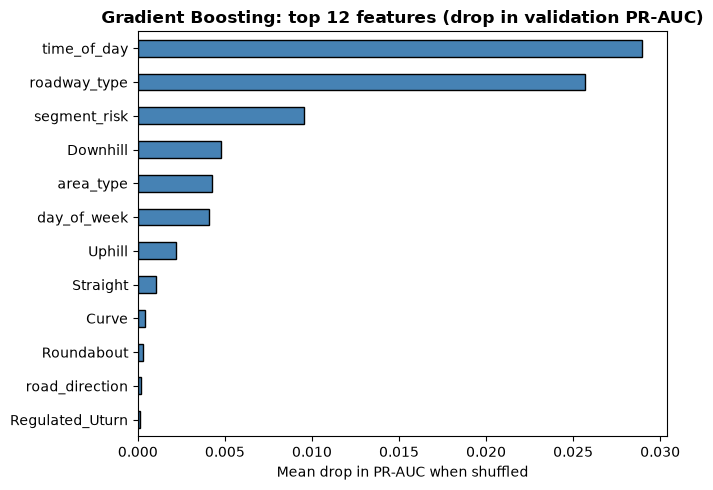

time_of_day     0.0290
roadway_type    0.0257
segment_risk    0.0095
Downhill        0.0048
area_type       0.0042
day_of_week     0.0041
Uphill          0.0022
Straight        0.0010
dtype: float64

In [20]:
perm = permutation_importance(hgb, X_val, y_val, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

ax = importance.tail(12).plot(kind="barh", color="steelblue", edgecolor="black", figsize=(7, 5))
ax.set_title("Gradient Boosting: top 12 features (drop in validation PR-AUC)", fontweight="bold")
ax.set_xlabel("Mean drop in PR-AUC when shuffled")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).head(8).round(4)

#### Dispatch impact

In [21]:
n_fatal = int(y_test.sum())
for name, p in [("Balanced LR + calibration", p_logreg_cal), ("Gradient Boosting + calibration", p_hgb_cal)]:
    recall, precision, lift = top_k_metrics(y_test, p)
    print(f"{name:33s} top 15% of calls -> {recall:.1%} of fatal crashes "
          f"({round(recall * n_fatal)} of {n_fatal}), lift {lift:.2f}x")

extra = (top_k_metrics(y_test, p_hgb_cal)[0] - top_k_metrics(y_test, p_logreg_cal)[0]) * n_fatal
print(f"\nSame ALS capacity: {extra:+.0f} fatal crashes reached in 2024-2025 with Gradient Boosting vs. the baseline.")
print(f"Calls above p* = {p_star:.0%}: {(p_hgb_cal >= p_star).mean():.1%} of test calls (capacity {CAPACITY:.0%}), "
      "so the Top-15% ranking stays the dispatch rule.")

Balanced LR + calibration         top 15% of calls -> 31.0% of fatal crashes (222 of 715), lift 2.07x
Gradient Boosting + calibration   top 15% of calls -> 31.5% of fatal crashes (225 of 715), lift 2.10x

Same ALS capacity: +3 fatal crashes reached in 2024-2025 with Gradient Boosting vs. the baseline.
Calls above p* = 5%: 57.8% of test calls (capacity 15%), so the Top-15% ranking stays the dispatch rule.


#### Takeaways (Pedro)

- **Gradient Boosting is the best tree model** (learning rate 0.03, 15 leaves, 150 trees): on Test 2024–2025 it reaches PR-AUC 0.126 and lift 2.10× at the Top 15%, against 0.122 and 2.08× for the balanced logistic regression. Random Forest ties with the baseline on ranking (lift 2.08×).
- **The gain over the baseline is small.** On Validation, boosting was clearly ahead (PR-AUC 0.134), but most of that edge does not carry over to the test years. With only road geometry, a km marker and calendar/time-of-day, the information available at t=0 caps how well any model can rank calls: the limit is the data, not the algorithm.
- **Calibration matters as much as the model.** Class weighting inflates probabilities (Brier 0.24); sigmoid calibration on Validation brings Brier to 0.064, in line with the base rate, without changing the ranking. Isotonic calibration was tried first but its ties cost about 1 point of recall at the Top 15%.
- **What drives the prediction:** time of day, roadway type (single vs. double carriageway) and the historical segment risk engineered in Task 2, followed by downhill segments, area type (rural) and day of week. These match the risk factors found in the EDA.
- **Training window:** using only post-2015 years gives the same validation ranking, so all Train years are kept.
- **For dispatch:** sending ALS to the 15% highest-risk calls reaches about 31% of fatal crashes, roughly twice what random allocation would reach. Since more than half of calls are above p* = 5%, capacity remains the binding constraint and the ranking is the decision rule.

### 7.2 Model 2: Non-tree models (Nuno)

**Why a neural network.** A multi-layer perceptron (MLP) also learns interactions between road, place and time, but through smooth combinations of all features at once instead of axis-aligned splits. Its inductive bias is genuinely different from the trees in 7.1, so it tells us whether the ceiling seen there comes from the algorithm or from the data.

Two non-tree approaches are compared:
- **MLP neural network** (main model), on the one-hot encoded and scaled features from Task 2 (`preprocessor`, frozen).
- **Linear Discriminant Analysis (LDA)**: a fast generative linear classifier, as a check on how far a linear boundary gets with the full feature set.

**Class imbalance.** scikit-learn's `MLPClassifier` has no class weights. Instead, each network is trained on **all fatal crashes plus a random sample of non-fatal ones** (random undersampling). A single network turned out to be unstable from one random seed to the next, so the model averages **5 networks, each with its own undersample and seed** (under-bagging). Probabilities are re-calibrated on Validation afterwards, as for the other models.

In [22]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neural_network import MLPClassifier


class UnderBaggedMLP(ClassifierMixin, BaseEstimator):
    """Average of n_models MLPs, each fitted on all fatal crashes + neg_ratio times as many random non-fatal ones."""

    def __init__(self, hidden_layer_sizes=(32, 16), alpha=1.0, neg_ratio=3, n_models=5, random_state=RANDOM_STATE):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.alpha = alpha
        self.neg_ratio = neg_ratio
        self.n_models = n_models
        self.random_state = random_state

    def fit(self, X, y):
        y = np.asarray(y)
        rng = np.random.RandomState(self.random_state)
        pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
        self.models_ = []
        for i in range(self.n_models):
            idx = np.concatenate([pos, rng.choice(neg, min(len(neg), self.neg_ratio * len(pos)), replace=False)])
            mlp = MLPClassifier(hidden_layer_sizes=self.hidden_layer_sizes, alpha=self.alpha,
                                early_stopping=True, n_iter_no_change=10, max_iter=300,
                                random_state=self.random_state + i)
            self.models_.append(mlp.fit(X[idx], y[idx]))
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models_], axis=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


def make_mlp(**params):
    # Encoder + scaler fitted on Train in Task 2, frozen so they are not refitted
    return Pipeline([("prep", FrozenEstimator(preprocessor)), ("model", UnderBaggedMLP(**params))])


def make_lda(**params):
    return Pipeline([("prep", FrozenEstimator(preprocessor)), ("model", LinearDiscriminantAnalysis(**params))])

#### Tuning on validation

For the MLP: network size, L2 penalty `alpha` and undersampling ratio (non-fatal crashes kept per fatal one). Each configuration is a bag of 5 networks, scored with the same `validation_score` as the trees. For LDA: plain vs. shrunk covariance estimate.

In [23]:
mlp_grid = [{"hidden_layer_sizes": h, "alpha": a, "neg_ratio": r}
            for h in [(16,), (32, 16)] for a in (0.1, 1.0) for r in (1, 3)]
lda_grid = [{"solver": "svd"}, {"solver": "lsqr", "shrinkage": "auto"}]

tuning_nontree = []
for params in mlp_grid:
    tuning_nontree.append({"Model": "MLP (5-bag)", "Params": params, **validation_score(make_mlp(**params))})
for params in lda_grid:
    tuning_nontree.append({"Model": "LDA", "Params": params, **validation_score(make_lda(**params))})

tuning_nontree = pd.DataFrame(tuning_nontree).sort_values("PR-AUC (val)", ascending=False)
tuning_nontree.round(4)

,Model,Params,PR-AUC (val),Lift@15% (val)
4,MLP (5-bag),"{'hidden_layer_sizes': (32, 16), 'alpha': 0.1,...",0.1295,2.1730
2,MLP (5-bag),"{'hidden_layer_sizes': (16,), 'alpha': 1.0, 'n...",0.1295,2.0781
1,MLP (5-bag),"{'hidden_layer_sizes': (16,), 'alpha': 0.1, 'n...",0.1289,2.2363
0,MLP (5-bag),"{'hidden_layer_sizes': (16,), 'alpha': 0.1, 'n...",0.1288,2.1414
6,MLP (5-bag),"{'hidden_layer_sizes': (32, 16), 'alpha': 1.0,...",0.1282,2.1624
7,MLP (5-bag),"{'hidden_layer_sizes': (32, 16), 'alpha': 1.0,...",0.1266,2.1097
5,MLP (5-bag),"{'hidden_layer_sizes': (32, 16), 'alpha': 0.1,...",0.1259,2.1097
3,MLP (5-bag),"{'hidden_layer_sizes': (16,), 'alpha': 1.0, 'n...",0.1251,2.1835
9,LDA,"{'solver': 'lsqr', 'shrinkage': 'auto'}",0.1231,2.0886
8,LDA,{'solver': 'svd'},0.1230,2.1097


In [24]:
best_mlp = tuning_nontree[tuning_nontree["Model"] == "MLP (5-bag)"].iloc[0]
best_mlp_params = best_mlp["Params"]
best_lda_params = tuning_nontree.loc[tuning_nontree["Model"] == "LDA", "Params"].iloc[0]
print(f"Best MLP: {best_mlp_params}")
print(f"Best LDA: {best_lda_params}")

Best MLP: {'hidden_layer_sizes': (32, 16), 'alpha': 0.1, 'neg_ratio': 1}
Best LDA: {'solver': 'lsqr', 'shrinkage': 'auto'}


#### Why a bag of networks

Same tuned settings, but one network at a time with 5 different seeds. The spread between seeds is as large as the differences between configurations in the grid, so a single network's score is partly luck; averaging 5 networks removes most of that noise.

In [25]:
singles = pd.DataFrame([validation_score(make_mlp(**best_mlp_params, n_models=1, random_state=seed))
                        for seed in range(5)], index=[f"Single MLP, seed {seed}" for seed in range(5)])
bag = best_mlp[["PR-AUC (val)", "Lift@15% (val)"]].rename("Bag of 5 MLPs")
pd.concat([singles, bag.to_frame().T]).astype(float).round(4)

,PR-AUC (val),Lift@15% (val)
"Single MLP, seed 0",0.1253,2.0148
"Single MLP, seed 1",0.1149,1.9515
"Single MLP, seed 2",0.1153,1.9620
"Single MLP, seed 3",0.1241,2.0148
"Single MLP, seed 4",0.1190,2.0992
Bag of 5 MLPs,0.1295,2.1730


#### Final fit, calibration and test-set scoring

Refit on Train, sigmoid calibration on Validation (model frozen, same choice and reasons as in 7.1), scored **once** on Test 2024–2025.

In [26]:
mlp = make_mlp(**best_mlp_params).fit(X_train, y_train)
lda = make_lda(**best_lda_params).fit(X_train, y_train)

mlp_cal = CalibratedClassifierCV(FrozenEstimator(mlp), method="sigmoid").fit(X_val, y_val)
lda_cal = CalibratedClassifierCV(FrozenEstimator(lda), method="sigmoid").fit(X_val, y_val)

p_mlp, p_mlp_cal = mlp.predict_proba(X_test)[:, 1], mlp_cal.predict_proba(X_test)[:, 1]
p_lda, p_lda_cal = lda.predict_proba(X_test)[:, 1], lda_cal.predict_proba(X_test)[:, 1]

results = pd.concat([results, pd.DataFrame([
    evaluate("LDA", y_test, p_lda),
    evaluate("LDA + sigmoid calibration", y_test, p_lda_cal),
    evaluate("MLP (5-bag)", y_test, p_mlp),
    evaluate("MLP (5-bag) + sigmoid calibration", y_test, p_mlp_cal),
])])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552
Balanced LR + isotonic calibration,0.6679,0.1180,0.3105,0.1471,2.0699,0.0645
Random Forest,0.6640,0.1245,0.3119,0.1478,2.0793,0.2331
Random Forest + sigmoid calibration,0.6640,0.1245,0.3119,0.1478,2.0793,0.0645
Gradient Boosting,0.6731,0.1264,0.3147,0.1491,2.0979,0.2417
Gradient Boosting + sigmoid calibration,0.6731,0.1264,0.3147,0.1491,2.0979,0.0644
LDA,0.6623,0.1174,0.2825,0.1339,1.8834,0.0656
LDA + sigmoid calibration,0.6623,0.1174,0.2825,0.1339,1.8834,0.0650
MLP (5-bag),0.6653,0.1180,0.3119,0.1478,2.0793,0.2703


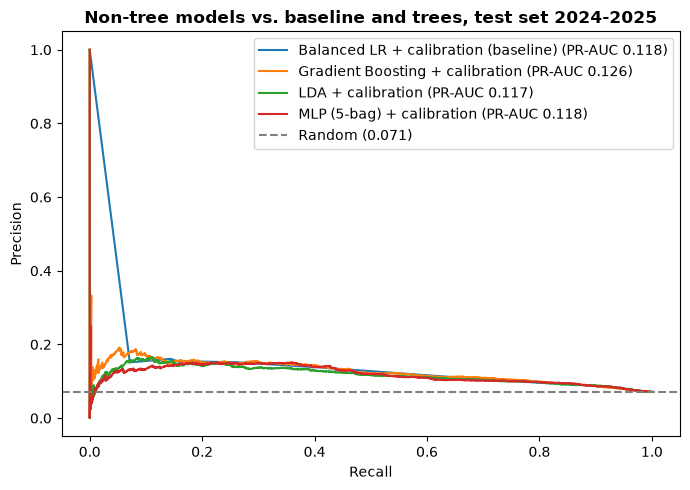

In [27]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in [("Balanced LR + calibration (baseline)", p_logreg_cal),
                ("Gradient Boosting + calibration", p_hgb_cal),
                ("LDA + calibration", p_lda_cal),
                ("MLP (5-bag) + calibration", p_mlp_cal)]:
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Random ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Non-tree models vs. baseline and trees, test set 2024-2025", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

#### What the network learned

Permutation importance on **Validation**, computed exactly as for Gradient Boosting in 7.1. The pipeline includes the encoder, so each one-hot encoded feature is shuffled as a whole and importances are reported per original feature.

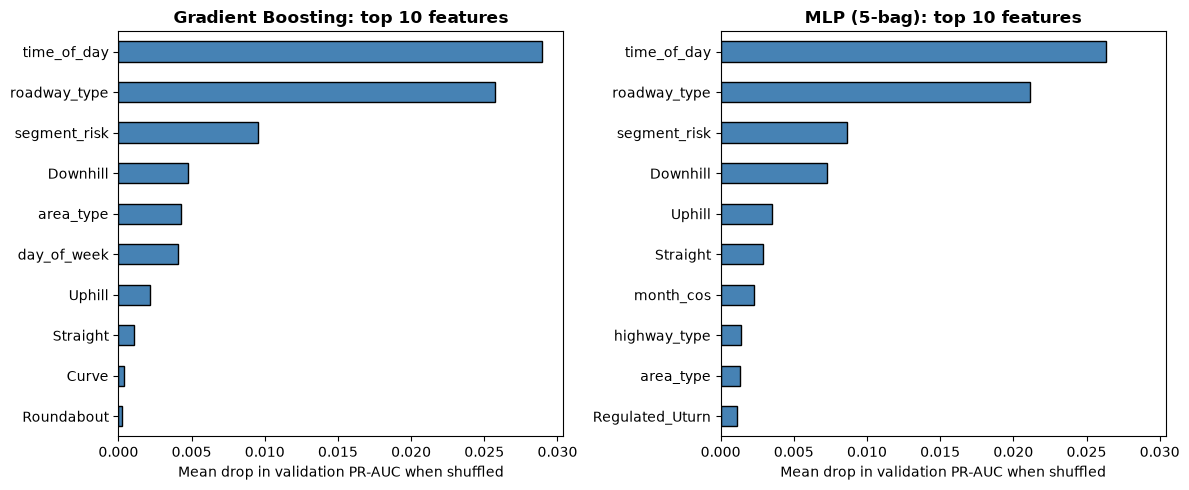

time_of_day     0.0263
roadway_type    0.0211
segment_risk    0.0086
Downhill        0.0072
Uphill          0.0035
Straight        0.0029
month_cos       0.0023
highway_type    0.0014
dtype: float64

In [28]:
perm_mlp = permutation_importance(mlp, X_val, y_val, scoring="average_precision",
                                  n_repeats=10, random_state=RANDOM_STATE)
importance_mlp = pd.Series(perm_mlp.importances_mean, index=FEATURES).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for ax, (name, imp) in zip(axes, [("Gradient Boosting", importance), ("MLP (5-bag)", importance_mlp)]):
    imp.tail(10).plot(kind="barh", color="steelblue", edgecolor="black", ax=ax)
    ax.set_title(f"{name}: top 10 features", fontweight="bold")
    ax.set_xlabel("Mean drop in validation PR-AUC when shuffled")
plt.tight_layout()
plt.show()
importance_mlp.sort_values(ascending=False).head(8).round(4)

#### Takeaways (Nuno)

- **Best non-tree model: a bag of 5 MLPs** (two hidden layers of 32 and 16 neurons, `alpha` 0.1, undersampled 1:1). Second on Validation (PR-AUC 0.130) after Gradient Boosting (0.135). On Test 2024–2025 it reaches 31.2% of fatal crashes at the Top 15% (223 of 715, lift 2.08×), ties Random Forest and is one crash ahead of the baseline; PR-AUC 0.118, Brier 0.065 after calibration.
- **Bagging was needed.** Single networks scored between 0.115 and 0.125 on Validation depending only on the seed; the average of 5 scored 0.130, above every single network.
- **LDA is the weakest model** (lift 1.88× on Test): a linear boundary without class balancing adds nothing over the balanced logistic regression.
- **The network learned the same risk factors as the trees:** time of day, roadway type, historical segment risk, then downhill/uphill and straight segments. Two very different algorithms agree on what drives fatality risk.
- **Main finding:** linear models, tree ensembles and neural networks all land at about 31% of fatal crashes with 15% of capacity (lift 2.1×). Three different model families hitting the same ceiling confirms Pedro's reading: with the information available at t=0, the limit is the data, not the algorithm. Section 8.4 tests the most promising missing piece of data, GPS location.

### 7.3 Final comparison (all models)

The winner is chosen on **Validation**, not on Test: picking the model with the best test score would turn the test set into a second validation set and overstate the result. Validation PR-AUC is computed before calibration; the sigmoid does not change the ranking, so it gives the same value after calibration.

In [29]:
final_models = {
    "Dummy (Baseline)": (None, "Dummy (Baseline)"),
    "Balanced LR + calibration": (logreg.predict_proba(val[BASE_FEATURES])[:, 1], "Balanced LR + isotonic calibration"),
    "Random Forest + calibration": (rf.predict_proba(X_val)[:, 1], "Random Forest + sigmoid calibration"),
    "Gradient Boosting + calibration": (hgb.predict_proba(X_val)[:, 1], "Gradient Boosting + sigmoid calibration"),
    "LDA + calibration": (lda.predict_proba(X_val)[:, 1], "LDA + sigmoid calibration"),
    "MLP (5-bag) + calibration": (mlp.predict_proba(X_val)[:, 1], "MLP (5-bag) + sigmoid calibration"),
}
final = pd.DataFrame({
    name: {"PR-AUC (val)": y_val.mean() if p_val is None else average_precision_score(y_val, p_val),
           **results.loc[row].add_suffix(" (test)")}
    for name, (p_val, row) in final_models.items()
}).T.sort_values("PR-AUC (val)", ascending=False)
final.round(4)

,PR-AUC (val),ROC-AUC (test),PR-AUC (test),Recall@15% (test),Precision@15% (test),Lift@15% (test),Brier (test)
Gradient Boosting + calibration,0.1347,0.6731,0.1264,0.3147,0.1491,2.0979,0.0644
MLP (5-bag) + calibration,0.1295,0.6653,0.1180,0.3119,0.1478,2.0793,0.0647
Random Forest + calibration,0.1273,0.6640,0.1245,0.3119,0.1478,2.0793,0.0645
Balanced LR + calibration,0.1234,0.6679,0.1180,0.3105,0.1471,2.0699,0.0645
LDA + calibration,0.1231,0.6623,0.1174,0.2825,0.1339,1.8834,0.0650
Dummy (Baseline),0.0697,0.5000,0.0711,0.1500,0.0711,1.0000,0.0711


In [30]:
winner = final.index[0]
p_final = {"Balanced LR + calibration": p_logreg_cal, "Random Forest + calibration": p_rf_cal,
           "Gradient Boosting + calibration": p_hgb_cal, "LDA + calibration": p_lda_cal,
           "MLP (5-bag) + calibration": p_mlp_cal}
print(f"Selected on validation: {winner}\n")
for name in ["Balanced LR + calibration", "Gradient Boosting + calibration", "MLP (5-bag) + calibration"]:
    recall, precision, lift = top_k_metrics(y_test, p_final[name])
    print(f"{name:33s} top 15% of calls -> {recall:.1%} of fatal crashes "
          f"({round(recall * n_fatal)} of {n_fatal}), lift {lift:.2f}x")

Selected on validation: Gradient Boosting + calibration

Balanced LR + calibration         top 15% of calls -> 31.0% of fatal crashes (222 of 715), lift 2.07x
Gradient Boosting + calibration   top 15% of calls -> 31.5% of fatal crashes (225 of 715), lift 2.10x
MLP (5-bag) + calibration         top 15% of calls -> 31.2% of fatal crashes (223 of 715), lift 2.08x


**Final model: Gradient Boosting + sigmoid calibration**, best on Validation (PR-AUC 0.135) and also best on Test: 31.5% of fatal crashes reached with 15% of ALS capacity (225 of 715 in 2024–2025), lift 2.10×, Brier 0.064.

The margin over the other models is small (2–3 fatal crashes over two years). If the authority prefers a model that is simpler to explain, the calibrated logistic regression gives almost the same dispatch result; Gradient Boosting is recommended because it is ahead on both Validation and Test and its probabilities are equally well calibrated.

## 8. Originality: from risk scores to decisions (Nuno)

Section 7 answers *how well* we can rank calls. This section turns the scores into decisions the authority can act on:

| Part | Question |
|---|---|
| 8.1 | What is the model worth, and how much ALS capacity pays off? (cost-benefit) |
| 8.2 | Where are the fatal-crash hotspots, and do they persist over time? (spatial risk) |
| 8.3 | Interactive hotspot map for the operations room (GIS) |
| 8.4 | What would GPS location add to the model? |

### 8.1 What is the model worth? Cost-benefit of ALS capacity

Using Joao's economics (ALS dispatch ≈ €2,500, fatal crash reached ≈ €50,000), sending ALS to the top-k share of calls gives, per 1,000 emergency calls:

$$\text{net benefit} = 1000 \cdot k \cdot (\text{precision@}k \cdot B - C)$$

The model and the baseline are compared with **random dispatch** (same number of ALS units, sent without a score). Results are per 1,000 calls so they do not depend on the size of the 150,000-crash sample.

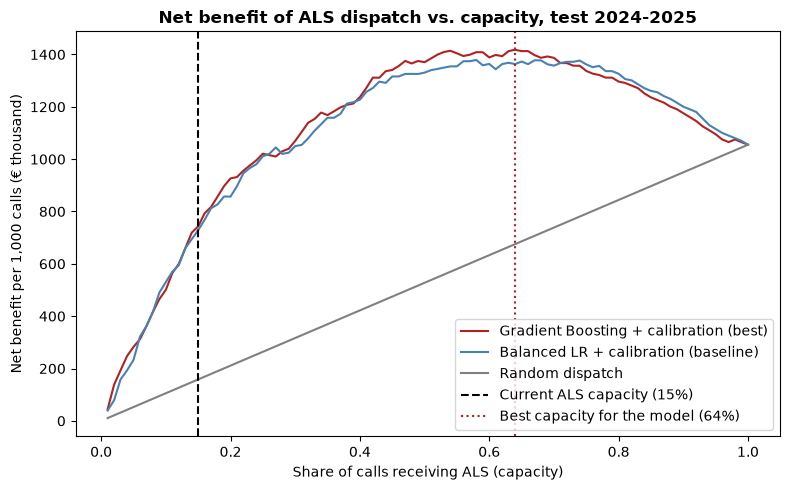

,Gradient Boosting + calibration (best) (€k),Balanced LR + calibration (baseline) (€k),Random dispatch (€k)
Capacity,,,
0.05,282.6,232.9,52.8
0.10,500.5,530.3,105.5
0.15,743.3,728.4,158.3
0.25,1020.8,1010.8,263.8
0.64,1418.0,1363.3,675.3


In [31]:
p_best = p_final[winner]
capacity_grid = np.round(np.arange(0.01, 1.001, 0.01), 2)


def net_benefit_per_1000(y_true, y_prob, k, benefit=BENEFIT_PREVENTED_DEATH, cost=COST_ALS):
    _, precision, _ = top_k_metrics(y_true, y_prob, k)
    return 1000 * k * (precision * benefit - cost)


curves = pd.DataFrame({
    name: [net_benefit_per_1000(y_test, p, k) for k in capacity_grid]
    for name, p in [(f"{winner} (best)", p_best), ("Balanced LR + calibration (baseline)", p_logreg_cal),
                    ("Random dispatch", p_dummy)]
}, index=capacity_grid)

ax = (curves / 1000).plot(figsize=(8, 5), color=["firebrick", "steelblue", "grey"])
ax.axvline(CAPACITY, ls="--", color="black", label=f"Current ALS capacity ({CAPACITY:.0%})")
best_k = curves.iloc[:, 0].idxmax()
ax.axvline(best_k, ls=":", color="firebrick", label=f"Best capacity for the model ({best_k:.0%})")
ax.set_xlabel("Share of calls receiving ALS (capacity)")
ax.set_ylabel("Net benefit per 1,000 calls (€ thousand)")
ax.set_title("Net benefit of ALS dispatch vs. capacity, test 2024-2025", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

curves.loc[[0.05, 0.10, 0.15, 0.25, best_k]].div(1000).round(1).rename_axis("Capacity").add_suffix(" (€k)")

In [32]:
_, precision_model, _ = top_k_metrics(y_test, p_best)
precision_random = y_test.mean()
value_added = net_benefit_per_1000(y_test, p_best, CAPACITY) - net_benefit_per_1000(y_test, p_dummy, CAPACITY)

print(f"At {CAPACITY:.0%} capacity, per 1,000 calls ({CAPACITY * 1000:.0f} ALS dispatches):")
print(f"  value added by the model vs. random dispatch: €{value_added:,.0f}")
print(f"  each ALS dispatch reaches a fatal crash {precision_model:.1%} of the time (random: {precision_random:.1%})")
print("\nBreak-even value of reaching a fatal crash (dispatch pays off above it):")
print(f"  with the model: €{COST_ALS / precision_model:,.0f}   ·   random dispatch: €{COST_ALS / precision_random:,.0f}")

At 15% capacity, per 1,000 calls (150 ALS dispatches):
  value added by the model vs. random dispatch: €585,027
  each ALS dispatch reaches a fatal crash 14.9% of the time (random: 7.1%)

Break-even value of reaching a fatal crash (dispatch pays off above it):
  with the model: €16,767   ·   random dispatch: €35,161


### 8.2 Where are the fatal hotspots?

The models in Section 7 cannot use GPS (it only exists from 2017, Task 2). For the GPS years, a direct spatial view is still possible:

1. Brazil is divided into a **1° × 1° grid** (≈ 110 km, roughly the range of one ALS / helicopter base).
2. Each cell's fatality rate is computed on **2017–2023** only, smoothed towards the overall rate as for segment risk in Task 2 (weight of 50 crashes).
3. **Hotspots** are the highest-risk cells that together hold 15% of the 2017–2023 crashes (the same 15% as ALS capacity).
4. **Out-of-time check:** do these hotspots still concentrate fatal crashes in 2024–2025, which they never saw?

The GPS coordinates are re-attached from the raw file. The prepared splits keep the raw row order, so the rows are matched one to one (checked on `km` and the target below). A few coordinates fall outside Brazil (e.g. latitude −85) and are left out of the grid.

In [33]:
import folium
from sklearn.model_selection import KFold

RAW = Path("../data/raw/highway_accidents.csv")
if not RAW.exists():
    RAW = Path("highway_accidents.csv")
    if not RAW.exists():
        from google.colab import files
        files.upload()  # highway_accidents.csv
raw = pd.read_csv(RAW, parse_dates=["date"])
raw = raw[raw.isnull().sum(axis=1) <= 10]  # same corrupted-row rule as Task 2
raw["year"] = raw["date"].dt.year

for split, years in [(train, raw["year"] <= 2021), (val, raw["year"].between(2022, 2023)), (test, raw["year"] >= 2024)]:
    source = raw[years]
    assert np.array_equal(source["km"].values, split["km"].values, equal_nan=True)
    assert np.array_equal((source["accident_classification"] == 2).astype(int).values, split["is_fatal"].values)
    split["lat"], split["lon"] = source["latitude"].values, source["longitude"].values

CELL_DEG = 1.0
SMOOTHING = 50  # same as segment risk in Task 2


def add_cell(data):
    in_brazil = data["lat"].between(-34, 6) & data["lon"].between(-74, -34)
    row = np.floor(data["lat"] / CELL_DEG).astype("Int64").astype(str)
    col = np.floor(data["lon"] / CELL_DEG).astype("Int64").astype(str)
    data["cell"] = np.where(in_brazil, row + "_" + col, "outside")


for split in (train, val, test):
    add_cell(split)

history = pd.concat([train[train["year"] >= 2017], val])
history = history[history["cell"] != "outside"]
prior_hist = history["is_fatal"].mean()
cells = history.groupby("cell").agg(crashes=("is_fatal", "size"), fatal=("is_fatal", "sum"),
                                    lat=("lat", "median"), lon=("lon", "median"))
cells["risk"] = (cells["fatal"] + SMOOTHING * prior_hist) / (cells["crashes"] + SMOOTHING)
cells = cells.sort_values("risk", ascending=False)
cells["hotspot"] = cells["crashes"].cumsum() / cells["crashes"].sum() <= CAPACITY
print(f"2017-2023: {len(history):,} crashes with GPS in {len(cells)} cells; "
      f"{cells['hotspot'].sum()} hotspot cells hold {CAPACITY:.0%} of them")

2017-2023: 33,704 crashes with GPS in 401 cells; 109 hotspot cells hold 15% of them


In [34]:
test_gps = test[test["cell"] != "outside"].copy()
test_gps["hotspot"] = test_gps["cell"].map(cells["hotspot"]).fillna(False).astype(bool)

persistence = test_gps.groupby("hotspot")["is_fatal"].agg(crashes="size", fatal="sum", fatal_rate="mean")
persistence["share of crashes"] = persistence["crashes"] / persistence["crashes"].sum()
persistence["share of fatal crashes"] = persistence["fatal"] / persistence["fatal"].sum()
persistence.index = persistence.index.map({True: "Hotspot cells", False: "Other cells"})
persistence.round(3)

,crashes,fatal,fatal_rate,share of crashes,share of fatal crashes
hotspot,,,,,
Other cells,8607,533,0.062,0.856,0.745
Hotspot cells,1449,182,0.126,0.144,0.255


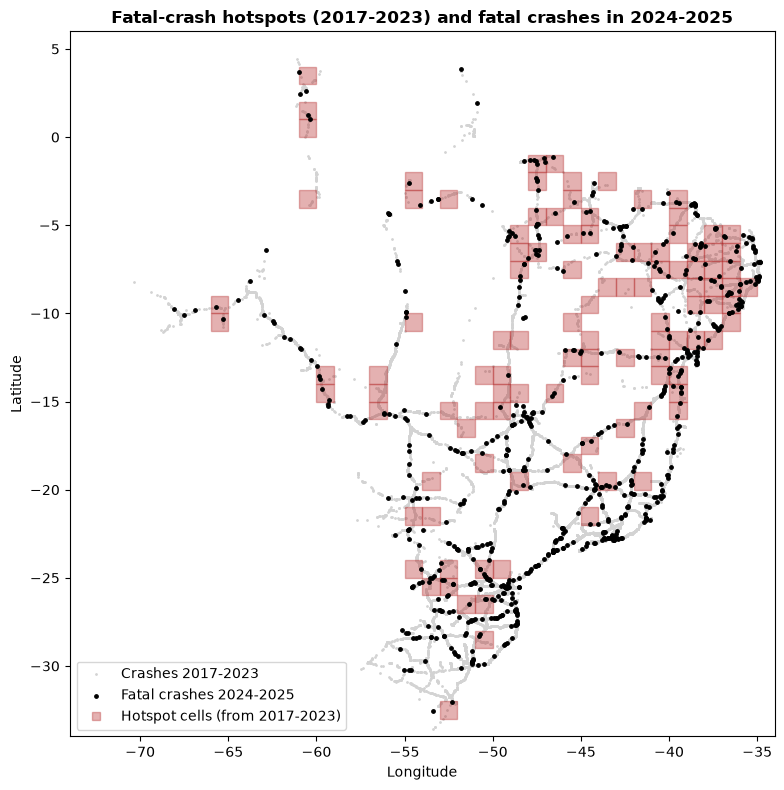

,crashes,fatal,risk,lat,lon
cell,,,,,
-9_-37,191,40,0.180,-8.497,-36.437
-12_-39,53,15,0.178,-11.698,-38.977
-15_-40,104,20,0.152,-14.786,-39.314
-14_-40,80,16,0.149,-13.452,-39.483
-12_-45,13,6,0.149,-11.878,-44.893
-10_-38,40,10,0.149,-9.299,-37.288
-6_-49,14,6,0.147,-5.448,-48.888
-7_-41,9,5,0.142,-6.371,-40.659
-9_-44,5,4,0.134,-8.154,-43.790


In [35]:
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(history["lon"], history["lat"], s=1, color="lightgrey", label="Crashes 2017-2023")
hot = cells[cells["hotspot"]]
for (row, col) in (map(int, c.split("_")) for c in hot.index):
    ax.add_patch(plt.Rectangle((col * CELL_DEG, row * CELL_DEG), CELL_DEG, CELL_DEG,
                               facecolor="firebrick", alpha=0.35, edgecolor="firebrick"))
fatal_test = test_gps[test_gps["is_fatal"] == 1]
ax.scatter(fatal_test["lon"], fatal_test["lat"], s=6, color="black", label="Fatal crashes 2024-2025")
ax.plot([], [], "s", color="firebrick", alpha=0.35, label="Hotspot cells (from 2017-2023)")
ax.set_xlim(-74, -34)
ax.set_ylim(-34, 6)
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Fatal-crash hotspots (2017-2023) and fatal crashes in 2024-2025", fontweight="bold")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
cells.loc[cells["hotspot"], ["crashes", "fatal", "risk", "lat", "lon"]].head(10).round(3)

### 8.3 Interactive hotspot map

A Folium map for the operations room, with three layers that can be switched on and off:
- **Grid cells** coloured by their 2017–2023 fatality rate (hover for crashes, deaths and rate).
- **Top-15% risk calls in 2024–2025**: the calls the best model would send ALS to.
- **Fatal crashes in 2024–2025**.

Saved as `reports/figures/task3_hotspot_map.html` (opens in any browser; not displayed inline to keep the notebook small).

In [36]:
risk_colors = plt.get_cmap("YlOrRd")
risk_max = cells["risk"].quantile(0.95)
fmap = folium.Map(location=[-15, -50], zoom_start=4, tiles="CartoDB positron")

grid_layer = folium.FeatureGroup(name="Grid cells: fatality rate 2017-2023")
for cell_id, c in cells[cells["crashes"] >= 20].iterrows():
    row, col = map(int, cell_id.split("_"))
    color = "#%02x%02x%02x" % tuple(int(255 * v) for v in risk_colors(min(c["risk"] / risk_max, 1))[:3])
    folium.Rectangle(
        bounds=[[row * CELL_DEG, col * CELL_DEG], [(row + 1) * CELL_DEG, (col + 1) * CELL_DEG]],
        color="firebrick" if c["hotspot"] else color, weight=2 if c["hotspot"] else 0.5,
        fill=True, fill_color=color, fill_opacity=0.6,
        tooltip=f"{'HOTSPOT · ' if c['hotspot'] else ''}{c['crashes']:.0f} crashes, "
                f"{c['fatal']:.0f} fatal · rate {c['risk']:.1%}",
    ).add_to(grid_layer)
grid_layer.add_to(fmap)

top_cut = np.quantile(p_best, 1 - CAPACITY)
top_layer = folium.FeatureGroup(name="Top-15% risk calls 2024-2025 (model)")
fatal_layer = folium.FeatureGroup(name="Fatal crashes 2024-2025")
for p, (_, r) in zip(p_best, test.iterrows()):
    if r["cell"] == "outside":
        continue
    if p >= top_cut:
        folium.CircleMarker([r["lat"], r["lon"]], radius=2, color="darkorange", fill=True,
                            tooltip=f"Predicted fatality risk {p:.1%}").add_to(top_layer)
    if r["is_fatal"] == 1:
        folium.CircleMarker([r["lat"], r["lon"]], radius=2, color="black", fill=True,
                            tooltip=f"Fatal crash · predicted risk {p:.1%}").add_to(fatal_layer)
top_layer.add_to(fmap)
fatal_layer.add_to(fmap)
folium.LayerControl(collapsed=False).add_to(fmap)

MAP_PATH = Path("../reports/figures") if Path("../reports/figures").exists() else Path(".")
fmap.save(MAP_PATH / "task3_hotspot_map.html")
print(f"Saved {(MAP_PATH / 'task3_hotspot_map.html').resolve()}")

Saved /Users/nunolopes/predictive-analytics-forecasting/reports/figures/task3_hotspot_map.html


### 8.4 What would GPS add to the model?

The hotspot check suggests location carries risk that the km band of `segment_risk` misses. To measure it, Gradient Boosting (tuned settings from 7.1) is trained on the **GPS years of Train (2017–2021)** twice: with the Section 7 features, and with one extra feature, `cell_risk`, the smoothed fatality rate of the crash's 1° cell.

Same leakage safeguards as segment risk in Task 2: out-of-fold on Train (5 folds), Validation and Test mapped with rates from Train 2017–2021 only. Both models are calibrated on Validation and scored on Test.

In [37]:
gps_train = train[train["year"] >= 2017].copy()
prior_gps = gps_train["is_fatal"].mean()


def cell_rates(fit_data):
    stats = fit_data.groupby("cell")["is_fatal"].agg(["sum", "count"])
    return (stats["sum"] + SMOOTHING * prior_gps) / (stats["count"] + SMOOTHING)


gps_train["cell_risk"] = prior_gps
for fit_idx, apply_idx in KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(gps_train):
    rates = cell_rates(gps_train.iloc[fit_idx])
    gps_train.iloc[apply_idx, gps_train.columns.get_loc("cell_risk")] = (
        gps_train.iloc[apply_idx]["cell"].map(rates).fillna(prior_gps).values)
for split in (val, test):
    split["cell_risk"] = split["cell"].map(cell_rates(gps_train)).fillna(prior_gps)

gps_results = {}
for name, feats in [("Gradient Boosting, Train 2017-2021", FEATURES),
                    ("+ GPS cell risk", FEATURES + ["cell_risk"])]:
    model = make_hgb(**best_hgb_params).fit(gps_train[feats], gps_train["is_fatal"])
    model_cal = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid").fit(val[feats], y_val)
    gps_results[name] = {"PR-AUC (val)": average_precision_score(y_val, model.predict_proba(val[feats])[:, 1]),
                         **evaluate(name, y_test, model_cal.predict_proba(test[feats])[:, 1]).add_suffix(" (test)")}

print(f"Train 2017-2021 with GPS: {len(gps_train):,} crashes")
gps_results = pd.DataFrame(gps_results).T
pd.concat([gps_results, final.loc[["Gradient Boosting + calibration"]]
           .rename(index={"Gradient Boosting + calibration": "Reference: Gradient Boosting, Train 2007-2021 (7.1)"})]).round(4)

Train 2017-2021 with GPS: 24,634 crashes


,PR-AUC (val),ROC-AUC (test),PR-AUC (test),Recall@15% (test),Precision@15% (test),Lift@15% (test),Brier (test)
"Gradient Boosting, Train 2017-2021",0.1315,0.6806,0.1313,0.3245,0.1537,2.1632,0.0642
+ GPS cell risk,0.1528,0.6936,0.1414,0.3301,0.1564,2.2005,0.0639
"Reference: Gradient Boosting, Train 2007-2021 (7.1)",0.1347,0.6731,0.1264,0.3147,0.1491,2.0979,0.0644


### Takeaways: originality (Nuno)

- **The model doubles the value of every ALS dispatch.** With 15% capacity, an ALS unit sent by the model reaches a fatal crash 14.9% of the time vs. 7.1% when sent without a score. Under Joao's economics this is worth about **€585,000 per 1,000 emergency calls** compared with random dispatch.
- **The conclusion does not rest on the €50,000 assumption.** Model-guided dispatch pays off as soon as reaching a fatal crash is worth more than about €16,800; random dispatch needs €35,200. Even if only one in three fatal crashes reached by ALS ends in a life saved, using the model still pays off.
- **Capacity:** net benefit keeps growing up to about 64% of calls, in line with the 58% of calls above p* = 5%. Under these economics ALS is undersized, but with diminishing returns: the first 15% of capacity is worth €743k per 1,000 calls, the next 10% only €278k more. Extra units should go to the highest-risk calls first, which is exactly what the score provides.
- **Fatal hotspots persist over time.** The 109 grid cells flagged on 2017–2023 hold 14% of the 2024–2025 crashes but **25.5% of the deaths**, with a fatality rate of 12.6% vs. 6.2% elsewhere. The highest-risk cells are in the North-East (Pernambuco and Bahia). These are candidate locations for ALS / helicopter bases and for road-safety inspections.
- **GPS is the most valuable missing information.** On the same training years (2017–2021), adding the location risk of the crash's 1° cell raises Validation PR-AUC from 0.132 to 0.153 and Test PR-AUC from 0.131 to 0.141 (lift 2.16× → 2.20×): a larger gain than any change of algorithm in Section 7. Recommendation: make GPS location mandatory at call intake and, once enough GPS years are available, retrain the dispatch model with location risk.
- **Limitations:** the 1° grid is coarse (no highway ID or exact road network); hotspot rates in cells with few crashes are smoothed but still noisy; the economic figures assume that a fatal crash reached by ALS is worth €50,000 and are reported per 1,000 calls because the data is a sample.